# Portfolio of Evidence (POE), Part 1
## Guess the Author: Identifying Victorian Novelists from Writing Style with an LSTM Recurrent Neural Network

---

| | |
|:---|:---|
| **Dataset** | Victorian Era Authorship Attribution |
| **Source** | https://archive.ics.uci.edu/dataset/454/victorian+era+authorship+attribution |
| **DOI** | https://doi.org/10.24432/C5SW4H |
| **Licence** | Creative Commons Attribution 4.0 International (CC BY 4.0) |

---

| | |
|:---|:---|
| **Module Code** | PDAN8412 |
| **Module Name** | Programming for Data Analytics 2 |
| **Assessment** | Portfolio of Evidence, Part 1 (Recurrent Neural Networks) |
| **Academic Year** | 2026 |

---

| | |
|:---|:---|
| **Student Name** | Khodani Mbovane |
| **Student No.** | ST10524773 |
| **Qualification** | Postgraduate Diploma in Data Analytics (NQF 8) |
| **Institution** | The Independent Institute of Education (IIE) / EMERIS |
| **Submission** |  |

---

**Declaration**

I declare that this Portfolio of Evidence is my own original work. All sources have been acknowledged using the Harvard referencing style. No part of this submission has been copied from any other source without proper acknowledgement.

**Code attribution:** Parts of the code structure in this notebook were drafted with the assistance of a large language model (Anthropic, 2026) and were then edited, restructured and extended by me. Library usage follows the official Apache Spark (Apache Software Foundation, 2024) and TensorFlow/Keras (Chollet, 2021) documentation. Cells that were adapted rather than written from scratch are marked with an `# Attribution:` comment.

**Signed:** K. Mbovane &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; **Date:** 2026-06-23

## Table of Contents

1. **Justification of the Dataset**
   - 1.1 Business Context
   - 1.2 Why this Dataset Suits an LSTM
   - 1.3 Why this Dataset over Common Alternatives
   - 1.4 Data Quality and Common Pitfalls
2. **Planning Stage**
   - 2.1 End-to-End Plan
   - 2.2 EDA Plan
   - 2.3 Feature Selection Plan
   - 2.4 Hyperparameter Plan
   - 2.5 Evaluation Plan
   - 2.6 Report Plan
   - 2.7 Additional Considerations from Research
3. **Conducting My Analysis**
   - 3.1 Environment Setup
   - 3.2 Loading the Data with Spark
   - 3.3 Exploratory Data Analysis (Spark)
   - 3.4 Data Cleaning (Spark)
   - 3.5 Scoping the Authors and Splitting the Data
   - 3.6 Feature Selection with Chi-Square P-Values (Spark ML)
   - 3.7 Preparing Sequences for the LSTM
   - 3.8 Benchmark Model (TF-IDF and Logistic Regression)
   - 3.9 Training Model 1 (Baseline LSTM)
4. **Model Evaluation and Retraining**
   - 4.1 Evaluating Model 1
   - 4.2 Retraining: Model 2 (Windowed Bidirectional LSTM)
   - 4.3 Model Comparison, Classification Report and Confusion Matrix
   - 4.4 Overfitting Check
   - 4.5 The Fan Bot: `guess_author()`
5. **Summary of Findings for the Report**
6. **Conclusion**
7. **Reference List**

## 1 Justification of the Dataset

### 1.1 Business Context

As the data analyst for a book press, I have been asked to build a bot that fans can play with: they paste in a passage and the bot guesses who wrote it. The task is therefore **authorship attribution**, which is a multi-class text classification problem where the signal is the author's style rather than the story's topic (Stamatatos, 2009). A press that publishes classic literature is a natural fit for Victorian novelists, since these are the backlist titles fans already know.

### 1.2 Why this Dataset Suits an LSTM

Upon reviewing the Victorian Era Authorship Attribution dataset, it became evident that it is well suited to a Long Short-Term Memory (LSTM) Recurrent Neural Network for four reasons.

**The data is sequential text.** Writing style lives in the order of words: how an author strings together function words, clauses and sentence rhythm. A bag-of-words model discards this order, whereas an LSTM reads the text token by token and carries a memory of what came before. Simple RNNs struggle to keep that memory over long sequences because of vanishing gradients (Bengio, Simard and Frasconi, 1994), which is exactly the problem the LSTM's input, forget and output gates were designed to solve (Hochreiter and Schmidhuber, 1997).

**Each record is long enough to carry style.** Every record is a fragment of 1,000 words (roughly two pages), which gives the network enough context to learn stylistic habits rather than guess from a single sentence (Gungor, 2018a).

**It is large and labelled.** The labelled training file contains tens of thousands of fragments across 45 authors, each tagged with an author ID, far above the 10,000 record minimum. Even after I scope the problem to the most represented authors, the modelling set remains above 10,000 records (verified in Section 3.5).

**It is dependable.** The dataset was built for a Master's thesis at Purdue University (Gungor, 2018b), is hosted on the UCI Machine Learning Repository with a DOI, carries a CC BY 4.0 licence, and has been used in peer-reviewed research presented at ICDAR 2021 (Badirli et al., 2021). It is unique enough to avoid the over-used Kaggle tutorials the brief warns about, while still being a documented, citable source.

### 1.3 Why this Dataset over Common Alternatives

| Candidate | Records | Why I did not choose it |
|:---|:---|:---|
| Spooky Author Identification (Kaggle) | ~19,500 sentences | Only three authors, single sentences, and hundreds of public notebooks, which creates a high plagiarism risk |
| Reuter 50 50 (UCI) | 5,000 documents | Below the 10,000 record minimum |
| Self-scraped Project Gutenberg books | Variable | No curation, so I would have to remove headers, licences and character names myself, with no documented quality process |
| **Victorian Era Authorship Attribution (UCI)** | **93,600 fragments in total** | **Selected: curated, documented, citable, long fragments, many authors** |

### 1.4 Data Quality and Common Pitfalls

A dataset is only as useful as its weaknesses are understood. The table below sets out the pitfalls I identified before touching the data, and how I handle each one.

| Pitfall | Why it matters | How I handle it |
|:---|:---|:---|
| **Topic and name leakage** | A model can "cheat" by memorising character names or place names rather than style | The creators removed the first and last 500 words of each book and kept only the 10,000 most common words in the corpus, which strips most names (Gungor, 2018a). This forces the model to learn style |
| **Removing stopwords** | In sentiment work (my PDAN8411 POE) stopwords are noise. In authorship they are the strongest signal, because function word habits are unconscious and stable (Mosteller and Wallace, 1964; Burrows, 2002) | I deliberately **keep** stopwords and prove their value in the EDA |
| **Fragment leakage** | Neighbouring fragments of the same book share vocabulary. If one lands in training and the next in testing, scores are optimistic | The training CSV has no book ID, so a grouped split is not possible. I split before any fitting, only create windows after the split, and report this as a limitation |
| **Padding** | Fragments shorter than 1,000 words were padded by the creators | I measure short and non-alphabetic fragments in the EDA and drop fragments under 200 words |
| **Class imbalance** | Some authors have many more fragments than others, which biases accuracy | Stratified splits, class weights, and macro F1 as the headline metric |
| **Encoding** | The CSV is not UTF-8, so a default read can fail or corrupt text | I read it with ISO-8859-1 (Latin-1) encoding |
| **Open-set test file** | The official test file includes five authors not in training and is unlabelled | I use only the labelled training file and create my own train, validation and test splits. The bot uses a confidence threshold so it can say "not sure" |
| **No punctuation or casing** | Punctuation is a known style marker and it has been removed | I acknowledge this as a ceiling on performance |
| **Historical English** | Style patterns are 19th century | The bot is scoped to classic authors, not modern writers |

> The texts are 19th century published novels in the public domain, and the dataset contains no personal information about living people. The analysis is therefore POPIA-compliant by default (Republic of South Africa, 2013).

## 2 Planning Stage

### 2.1 End-to-End Plan

| **Stage** | **What Will Be Done** | **Tool / Method** |
|:---|:---|:---|
| **1. Setup** | Install PySpark, start a Spark session, fix random seeds for reproducibility | pyspark, TensorFlow |
| **2. Load** | Download the UCI archive and read the labelled CSV (Latin-1) into Spark | Spark DataFrame |
| **3. EDA** | Nulls, duplicates, class balance, fragment length, padding, lexical style metrics, function word profiles | Spark SQL, matplotlib, seaborn |
| **4. Clean** | Lowercase, strip non-letters, drop duplicates and fragments under 200 words, **keep stopwords** | Spark |
| **5. Scope** | Keep the most represented authors (minimum 10) until the modelling set has at least 10,000 fragments | Spark, pandas |
| **6. Split** | Stratified 70 / 15 / 15 train, validation, test split **before** any fitting | scikit-learn |
| **7. Feature selection** | Chi-square test of independence with p-values on training data; keep words with p < 0.05 plus the 100 most frequent function words | Spark ML `ChiSquareTest` |
| **8. Benchmark** | TF-IDF and Logistic Regression as a non-sequential reference point | scikit-learn |
| **9. Model 1** | Single-layer LSTM on the first 300 tokens of each fragment | TensorFlow / Keras |
| **10. Evaluate** | Accuracy, macro F1, top-3 accuracy, log loss, learning curves | scikit-learn metrics |
| **11. Model 2 (retrain)** | 250-word windows, stacked bidirectional LSTM, dropout, class weights, early stopping | Keras |
| **12. Fan bot** | `guess_author()` returns the top 3 authors and a confidence check | Python |
| **13. Report** | Succinct PDF report for the client | Word, exported to PDF |

### 2.2 EDA Plan

| Check | Question it answers | Decision it drives |
|:---|:---|:---|
| Nulls and duplicates | Is the data complete and unique? | Drop before modelling |
| Fragments per author | Is there class imbalance? | Author scope, class weights, macro F1 |
| Words per fragment and non-alphabetic tokens | Is padding present? | Minimum length filter |
| Type-token ratio and average word length per author | Do authors differ measurably in style? | Confirms the task is learnable |
| Function word rates per author | Do stopwords carry author signal? | Keep stopwords in the vocabulary |
| Most frequent words | What does the vocabulary look like? | Vocabulary and sequence length choices |

### 2.3 Feature Selection Plan

Backward and forward elimination with p-values are designed for tabular regression models. In a sequence model the "features" are the **vocabulary** the network can see and the **sequence length** it reads. I therefore apply the same statistical idea to the vocabulary: a chi-square test of independence between each word's presence and the author label, keeping words with p < 0.05 (Yang and Pedersen, 1997). Because very common function words appear in every fragment, their presence cannot be tested this way, so the 100 most frequent words are kept by design. Sequence length is chosen from the fragment length distribution found in the EDA.

### 2.4 Hyperparameter Plan

| Hyperparameter | Model 1 (baseline) | Model 2 (retrain) | Reason |
|:---|:---|:---|:---|
| Input length | First 300 tokens | 250-token windows, all windows used | Windows use the whole fragment and create more training sequences |
| Embedding size | 100 | 128 | Richer word representations |
| Recurrent layers | 1 x LSTM(64) | BiLSTM(64) then BiLSTM(32) | Bidirectional reading captures context on both sides (Schuster and Paliwal, 1997) |
| Regularisation | None | SpatialDropout 0.2, Dropout 0.4 / 0.3 | Reduce overfitting (Srivastava et al., 2014) |
| Optimiser | Adam, lr = 0.001 | Adam, lr = 0.001, clipnorm = 1.0, ReduceLROnPlateau | Stable training (Kingma and Ba, 2015) |
| Batch size / epochs | 64 / 10 | 128 / up to 20 with EarlyStopping (patience 3) | Stop when validation loss stops improving (Prechelt, 1998) |
| Class weights | No | Balanced | Address imbalance |
| Loss | Sparse categorical cross-entropy | Same | Multi-class, integer labels |

### 2.5 Evaluation Plan

| Metric | Why I use it |
|:---|:---|
| **Macro F1** (headline) | Treats every author equally, so a model cannot look good by only predicting the largest authors (Sokolova and Lapalme, 2009) |
| Accuracy | Easy for the client to understand |
| **Top-3 accuracy** | Matches the fan bot, which shows three guesses |
| Log loss | Checks whether the probabilities the bot shows are trustworthy |
| Per-author precision and recall | Shows which authors are easy or hard to identify |
| Confusion matrix | Shows which authors are confused with each other |
| Learning curves | Detects overfitting and underfitting |

### 2.6 Report Plan

| Report section | Content |
|:---|:---|
| 1. Purpose and data | The fan bot, the dataset, why it suits an LSTM |
| 2. Data cleaning | What was removed and why (duplicates, padding, encoding) |
| 3. EDA findings | Class balance, fragment length, style metrics, function word heatmap |
| 4. Model training | Vocabulary selection, architecture and hyperparameters of both models |
| 5. Results | Comparison table, confusion matrix, per-author results |
| 6. Accuracy and effectiveness | How the retrain addressed Model 1's shortcomings, limitations, next steps |

### 2.7 Additional Considerations from Research

- **Linear models are strong on this dataset.** Badirli et al. (2021) report that a linear classifier reaches very high accuracy in the closed-set setting. I therefore include a TF-IDF benchmark so that the LSTM is judged honestly rather than in isolation.
- **Open-set risk.** A fan may paste text by an author the model has never seen. The bot shows a "not confident" message when the top probability is below a threshold.
- **GPU efficiency.** I keep LSTM layers in their cuDNN-compatible form (default activations, no recurrent dropout) and use dropout layers between them instead, so training runs on Colab's GPU in reasonable time.

## 3 Conducting My Analysis

### 3.1 Environment Setup

> Run this notebook in Google Colab with a GPU runtime (Runtime > Change runtime type > T4 GPU).

In [1]:
# PySpark is not pre-installed on Colab; TensorFlow is
!pip install -q pyspark

In [2]:
# Loading libraries
import os, re, glob, random, zipfile, urllib.request
import numpy as np                                   # Maths functions
import pandas as pd                                  # Data handling after Spark aggregation
import matplotlib.pyplot as plt                      # Plotting
import seaborn as sns                                # Heatmaps
import warnings
warnings.filterwarnings("ignore")

# Spark: used for loading, EDA, cleaning and chi-square feature selection
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import CountVectorizer
from pyspark.ml.stat import ChiSquareTest

# TensorFlow / Keras: used for the LSTM models
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# scikit-learn: splitting, benchmark model and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, log_loss,
                             classification_report, confusion_matrix)

# Reproducibility: the same seed everywhere
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Starting Spark (6 GB driver memory fits inside a standard Colab runtime)
spark = (SparkSession.builder.appName("GuessTheAuthor_LSTM")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.execution.arrow.pyspark.enabled", "true")
         .getOrCreate())

print("Spark version     :", spark.version)
print("TensorFlow version:", tf.__version__)
print("GPU available     :", tf.config.list_physical_devices("GPU"))

Spark version     : 4.0.4
TensorFlow version: 2.20.0
GPU available     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 3.2 Loading the Data with Spark



In [3]:
# Downloading the UCI archive
URL = "https://archive.ics.uci.edu/static/public/454/victorian+era+authorship+attribution.zip"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/victorian.zip"):
    urllib.request.urlretrieve(URL, "data/victorian.zip")

# The archive can contain a zip inside a zip, so I keep extracting until none are left
done = set()
while True:
    new_zips = [z for z in glob.glob("data/**/*.zip", recursive=True) if z not in done]
    if not new_zips:
        break
    for z in new_zips:
        with zipfile.ZipFile(z) as zf:
            zf.extractall(os.path.dirname(z))
        done.add(z)

# Only the labelled training file is used (the official test file is unlabelled and open-set)
TRAIN_PATH = [p for p in glob.glob("data/**/*.csv", recursive=True) if "train" in p.lower()][0]
print("Training file:", TRAIN_PATH)

Training file: data/dataset/Gungor_2018_VictorianAuthorAttribution_data-train.csv


In [4]:
# Reading the CSV into Spark with Latin-1 encoding (the file is not UTF-8)
sdf_raw = (spark.read
           .option("header", True)
           .option("encoding", "ISO-8859-1")
           .option("multiLine", True)
           .option("escape", '"')
           .csv(TRAIN_PATH)
           .withColumn("author", F.col("author").cast("int")))

sdf_raw.printSchema()
print("Records:", sdf_raw.count(), "| Distinct authors:", sdf_raw.select("author").distinct().count())
sdf_raw.show(3, truncate=120)

root
 |-- text: string (nullable = true)
 |-- author: integer (nullable = true)

Records: 53678 | Distinct authors: 45
+------------------------------------------------------------------------------------------------------------------------+------+
|                                                                                                                    text|author|
+------------------------------------------------------------------------------------------------------------------------+------+
|ou have time to listen i will give you the entire story he said it may form the basis of a future novel and prove qui...|     1|
|wish for solitude he was twenty years of age and in the possession of perfect health most youths like him would have ...|     1|
|and the skirt blew in perfect freedom about the upper parts she wore no hat and her hair hung in a careless to the le...|     1|
+----------------------------------------------------------------------------------------------------

### 3.3 Exploratory Data Analysis (Spark)

All EDA below is computed in Spark (Zaharia et al., 2016). Only small aggregated results are converted to pandas for plotting.

#### 3.3.1 Completeness and Duplicates

In [5]:
# Null count per column
sdf_raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in sdf_raw.columns]).show()

# Exact duplicate fragments
total_rows  = sdf_raw.count()
unique_rows = sdf_raw.dropDuplicates(["text"]).count()
print(f"Duplicate fragments: {total_rows - unique_rows} ({(total_rows - unique_rows) / total_rows:.2%})")

+----+------+
|text|author|
+----+------+
|   0|     0|
+----+------+

Duplicate fragments: 0 (0.00%)


#### 3.3.2 Class Balance (Fragments per Author)

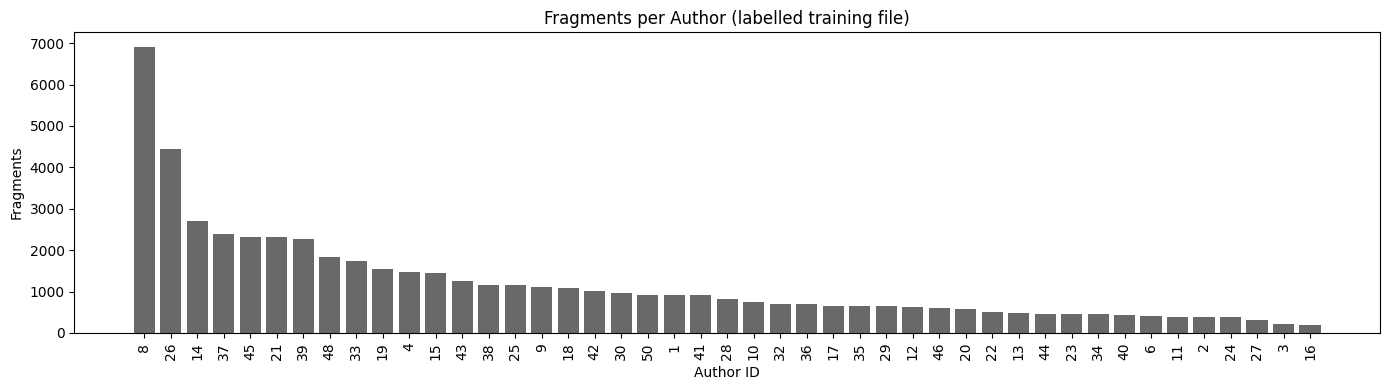

Largest author : 6,914 fragments
Smallest author: 183 fragments
Imbalance ratio: 37.8 : 1


In [6]:
author_counts = (sdf_raw.dropna().groupBy("author").count()
                 .orderBy(F.desc("count")).toPandas())

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(author_counts["author"].astype(str), author_counts["count"], color="dimgrey")
ax.set_title("Fragments per Author (labelled training file)")
ax.set_xlabel("Author ID"); ax.set_ylabel("Fragments")
plt.xticks(rotation=90); plt.tight_layout(); plt.show()

print(f"Largest author : {author_counts['count'].max():,} fragments")
print(f"Smallest author: {author_counts['count'].min():,} fragments")
print(f"Imbalance ratio: {author_counts['count'].max() / author_counts['count'].min():.1f} : 1")



#### 3.3.3 Fragment Length, Padding and Style Metrics

In [7]:
# Tokenising on whitespace in Spark and building simple stylometric features
sdf_feat = (sdf_raw.dropna()
    .withColumn("tokens", F.split(F.trim(F.lower(F.col("text"))), r"\s+"))
    .withColumn("word_count", F.size("tokens"))
    .withColumn("unique_words", F.size(F.array_distinct("tokens")))
    .withColumn("ttr", F.col("unique_words") / F.col("word_count"))            # type-token ratio
    .withColumn("avg_word_len",
                F.expr("aggregate(transform(tokens, x -> length(x)), 0, (acc, v) -> acc + v)")
                / F.col("word_count"))
    .withColumn("non_alpha", F.expr("size(filter(tokens, x -> NOT x rlike '^[a-z]+$'))")))

sdf_feat.select("word_count", "unique_words", "ttr", "avg_word_len", "non_alpha") \
        .summary("mean", "min", "25%", "50%", "75%", "max").show()

print("Fragments under 1,000 words:", sdf_feat.filter("word_count < 1000").count())
print("Fragments under 200 words  :", sdf_feat.filter("word_count < 200").count())

+-------+----------+------------------+------------------+-----------------+-----------------+
|summary|word_count|      unique_words|               ttr|     avg_word_len|        non_alpha|
+-------+----------+------------------+------------------+-----------------+-----------------+
|   mean|    1000.0|400.49018219754834|0.4004901821975457|3.942966913819434|9.324136517754015|
|    min|      1000|               104|             0.104|            1.286|                0|
|    25%|      1000|               381|             0.381|             3.81|                3|
|    50%|      1000|               403|             0.403|            3.956|                6|
|    75%|      1000|               423|             0.423|            4.101|               11|
|    max|      1000|               529|             0.529|             4.76|              334|
+-------+----------+------------------+------------------+-----------------+-----------------+

Fragments under 1,000 words: 0
Fragments under 20

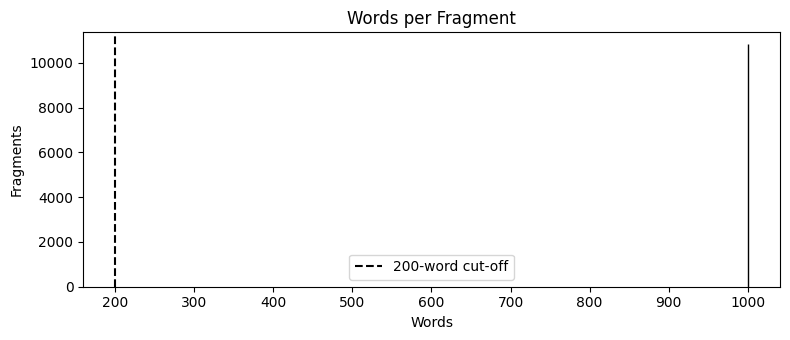

In [8]:
# Distribution of words per fragment (a 20% sample is enough for a histogram)
wc = sdf_feat.select("word_count").sample(fraction=0.2, seed=SEED).toPandas()
plt.figure(figsize=(8, 3.5))
plt.hist(wc["word_count"], bins=50, color="dimgrey", edgecolor="black")
plt.axvline(200, color="black", linestyle="--", label="200-word cut-off")
plt.title("Words per Fragment"); plt.xlabel("Words"); plt.ylabel("Fragments"); plt.legend()
plt.tight_layout(); plt.show()

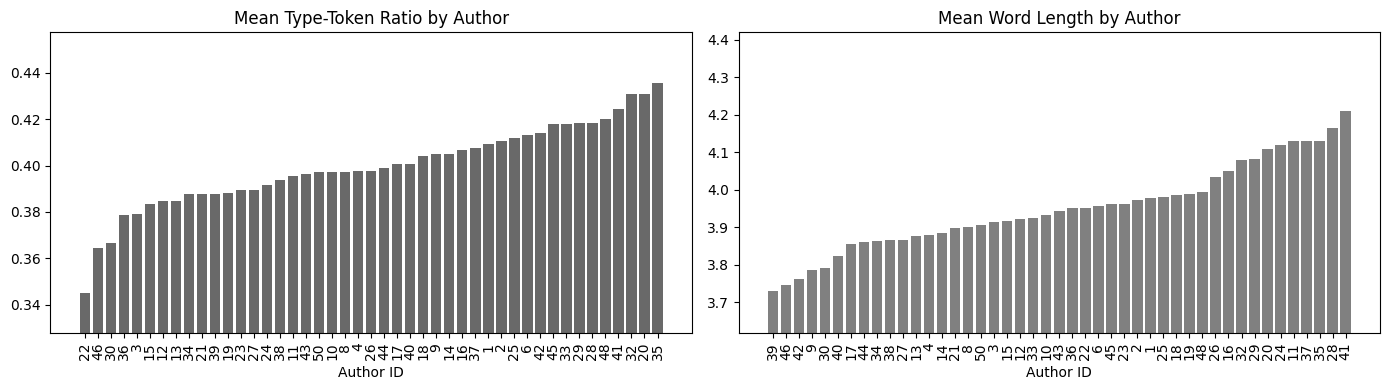

In [9]:
# Style metrics per author: do authors differ in vocabulary richness and word length?
style = (sdf_feat.groupBy("author")
         .agg(F.mean("ttr").alias("mean_ttr"), F.mean("avg_word_len").alias("mean_word_len"))
         .toPandas().sort_values("mean_ttr"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(style["author"].astype(str), style["mean_ttr"], color="dimgrey")
axes[0].set_title("Mean Type-Token Ratio by Author"); axes[0].set_ylim(style["mean_ttr"].min() * 0.95, None)
style_wl = style.sort_values("mean_word_len")
axes[1].bar(style_wl["author"].astype(str), style_wl["mean_word_len"], color="grey")
axes[1].set_title("Mean Word Length by Author"); axes[1].set_ylim(style_wl["mean_word_len"].min() * 0.97, None)
for ax in axes:
    ax.tick_params(axis="x", rotation=90); ax.set_xlabel("Author ID")
plt.tight_layout(); plt.show()

**My comment:** Most fragments sit at the full 1,000 words, with a small tail of shorter, padded fragments that I remove with the 200-word cut-off. The type-token ratio and average word length differ between authors even on these very simple measures, which confirms that style is measurable in this data and the task is learnable. An LSTM should be able to pick up far richer patterns than these two averages.

#### 3.3.4 Most Frequent Words and Function Word Profiles

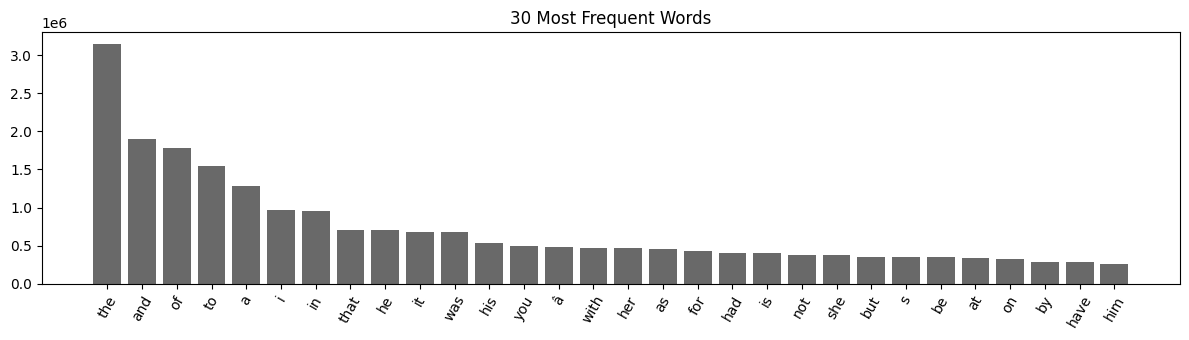

In [10]:
# 30 most frequent words across the corpus
top_words = (sdf_feat.select(F.explode("tokens").alias("w"))
             .groupBy("w").count().orderBy(F.desc("count")).limit(30).toPandas())

plt.figure(figsize=(12, 3.5))
plt.bar(top_words["w"], top_words["count"], color="dimgrey")
plt.title("30 Most Frequent Words"); plt.xticks(rotation=60)
plt.tight_layout(); plt.show()

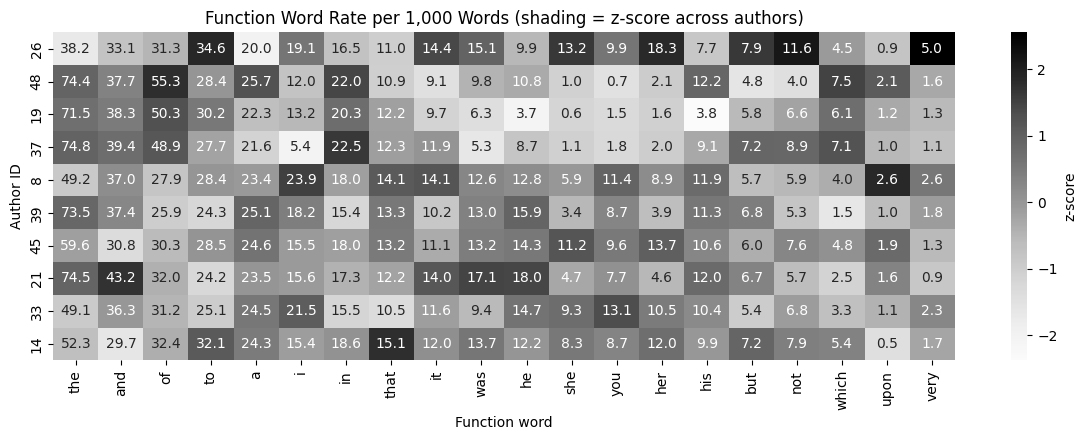

In [11]:
# Function word usage per 1,000 words for the 10 largest authors
FUNC_WORDS = ["the", "and", "of", "to", "a", "i", "in", "that", "it", "was",
              "he", "she", "you", "her", "his", "but", "not", "which", "upon", "very"]
top10_raw = author_counts["author"].head(10).tolist()

fw = (sdf_feat.filter(F.col("author").isin(top10_raw))
      .select("author", F.explode("tokens").alias("w"))
      .groupBy("author")
      .agg(F.count("*").alias("total"),
           *[F.sum((F.col("w") == w).cast("int")).alias(w) for w in FUNC_WORDS])
      .toPandas().set_index("author"))

fw_rate = fw[FUNC_WORDS].div(fw["total"], axis=0) * 1000
fw_z = (fw_rate - fw_rate.mean()) / fw_rate.std()          # standardised so words are comparable

plt.figure(figsize=(12, 4.5))
sns.heatmap(fw_z, cmap="Greys", center=0, annot=fw_rate.round(1), fmt="", cbar_kws={"label": "z-score"})
plt.title("Function Word Rate per 1,000 Words (shading = z-score across authors)")
plt.xlabel("Function word"); plt.ylabel("Author ID")
plt.tight_layout(); plt.show()

**My comment:** The most frequent words are almost entirely function words. In my previous text POE these would have been removed as noise, but the heatmap shows why that would be a mistake here: [name one or two examples after running, for example "Author X uses *upon* far more than the others, while Author Y leans on *very* and *she*"]. These unconscious habits are the fingerprint an authorship model needs (Burrows, 2002). **This EDA finding directly shapes training: stopwords stay in the text, and the 100 most frequent words are always kept in the LSTM vocabulary.**

### 3.4 Data Cleaning (Spark)

Acting on what the EDA showed: nulls and duplicates are dropped, any non-letter characters (including padding artefacts) are removed, and fragments under 200 words are excluded. Stopwords are kept on purpose.

In [12]:
MIN_WORDS = 200

sdf_clean = (sdf_raw.dropna(subset=["text", "author"])
    .dropDuplicates(["text"])
    .withColumn("text", F.lower(F.col("text")))
    .withColumn("text", F.regexp_replace("text", r"[^a-z\s]", " "))       # letters only
    .withColumn("text", F.trim(F.regexp_replace("text", r"\s+", " ")))    # collapse whitespace
    .withColumn("word_count", F.size(F.split("text", " ")))
    .filter(F.col("word_count") >= MIN_WORDS))

print("Records before cleaning:", sdf_raw.count())
print("Records after cleaning :", sdf_clean.count())

Records before cleaning: 53678
Records after cleaning : 53678


### 3.5 Scoping the Authors and Splitting the Data

Training on all 45 authors is possible, but for a fan bot a focused set of well-represented authors gives each class enough examples to learn from and keeps GPU training time practical. I keep the largest authors (at least 10) until the modelling set holds at least 10,000 fragments.

In [13]:
counts_clean = sdf_clean.groupBy("author").count().orderBy(F.desc("count")).toPandas()
cum = counts_clean["count"].cumsum()
N_AUTHORS = max(10, int((cum < 10000).sum()) + 1)
TOP_AUTHORS = counts_clean["author"].head(N_AUTHORS).tolist()

sdf_model = sdf_clean.filter(F.col("author").isin(TOP_AUTHORS))
n_model = sdf_model.count()
print(f"Authors kept: {N_AUTHORS} -> {TOP_AUTHORS}")
print(f"Modelling records: {n_model:,}")
assert n_model >= 10000, "The modelling set must hold at least 10,000 records"

# Moving the scoped data to pandas for splitting and Keras
pdf = sdf_model.select("text", "author", "word_count").toPandas()
le = LabelEncoder()
pdf["label"] = le.fit_transform(pdf["author"])
N_CLASSES = len(le.classes_)
# Author IDs can be mapped to names using the readme in the UCI archive
CLASS_NAMES = [f"Author_{a}" for a in le.classes_]

Authors kept: 10 -> [8, 26, 14, 37, 45, 21, 39, 48, 33, 19]
Modelling records: 28,433


In [14]:
# Stratified 70 / 15 / 15 split, done BEFORE any vocabulary or model fitting to prevent leakage
train_df, temp_df = train_test_split(pdf, test_size=0.30, stratify=pdf["label"], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

y_train, y_val, y_test = train_df["label"].values, val_df["label"].values, test_df["label"].values
print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")
print(pd.crosstab(pdf["label"], "count").T)

Train: 19,903 | Validation: 4,265 | Test: 4,265
label     0     1     2     3     4     5     6     7     8     9
col_0                                                            
count  6914  2696  1543  2307  4441  1742  2387  2266  2312  1825


### 3.6 Feature Selection with Chi-Square P-Values (Spark ML)

For every word in the training vocabulary I test the null hypothesis that the word's presence is independent of the author. Words with p < 0.05 are kept. Presence is binary (`binary=True`), which makes each word a valid categorical variable for the chi-square test. The test is fitted on the **training split only**.

In [15]:
# Attribution: ChiSquareTest usage adapted from the Apache Spark MLlib documentation (Apache Software Foundation, 2024)
train_sdf = (spark.createDataFrame(train_df[["text", "label"]])
             .withColumn("tokens", F.split("text", " "))
             .withColumn("label", F.col("label").cast("double")))

cv = CountVectorizer(inputCol="tokens", outputCol="bow", vocabSize=10000, minDF=5, binary=True)
cv_model = cv.fit(train_sdf)
train_bow = cv_model.transform(train_sdf)

chi = ChiSquareTest.test(train_bow, "bow", "label").head()
chi_df = pd.DataFrame({"word": cv_model.vocabulary,
                       "chi2": chi.statistics.toArray(),
                       "p_value": chi.pValues.toArray()})

ALPHA = 0.05
significant = chi_df.loc[chi_df["p_value"] < ALPHA, "word"].tolist()
ALWAYS_KEEP = cv_model.vocabulary[:100]     # Spark orders the vocabulary by corpus frequency
SELECTED_VOCAB = [w for w in dict.fromkeys(ALWAYS_KEEP + significant) if w]

print(f"Candidate words          : {len(chi_df):,}")
print(f"Significant at p < {ALPHA}  : {len(significant):,}")
print(f"Final LSTM vocabulary    : {len(SELECTED_VOCAB):,}")
print("Function words retained  :", [w for w in FUNC_WORDS if w in SELECTED_VOCAB])

Candidate words          : 9,977
Significant at p < 0.05  : 9,929
Final LSTM vocabulary    : 9,930
Function words retained  : ['the', 'and', 'of', 'to', 'a', 'i', 'in', 'that', 'it', 'was', 'he', 'she', 'you', 'her', 'his', 'but', 'not', 'which', 'upon', 'very']


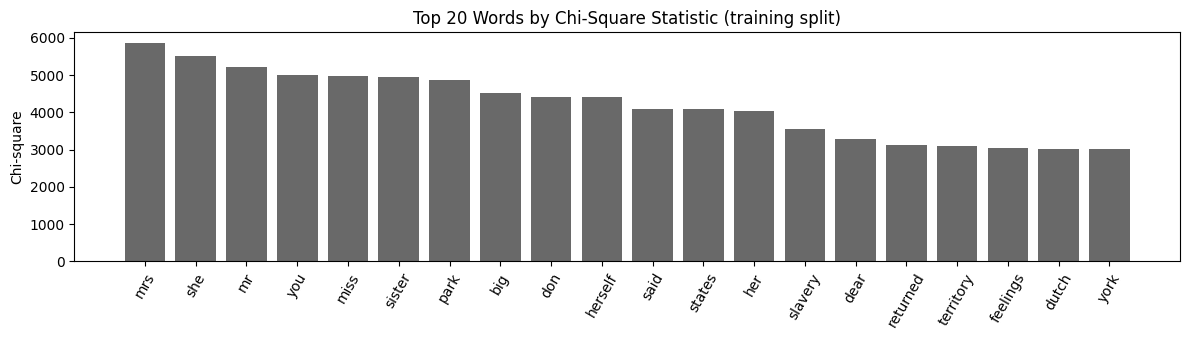

In [16]:
# The 20 most author-dependent words
top_chi = chi_df.sort_values("chi2", ascending=False).head(20)
plt.figure(figsize=(12, 3.5))
plt.bar(top_chi["word"], top_chi["chi2"], color="dimgrey")
plt.title("Top 20 Words by Chi-Square Statistic (training split)")
plt.xticks(rotation=60); plt.ylabel("Chi-square")
plt.tight_layout(); plt.show()

**My comment:**  The chi-square test removes words whose presence is statistically unrelated to the author, which shrinks the embedding layer and the number of parameters the LSTM must learn. Words outside the selected vocabulary are not deleted from the text; they become an out-of-vocabulary token, so the **sequence structure is preserved**, which matters for an RNN. With thousands of tests some words will pass by chance (about 5% at this alpha), which I accept because the goal is dimensionality reduction rather than formal inference.

### 3.7 Preparing Sequences for the LSTM

The EDA showed fragments of about 1,000 words. For Model 1 I read the first 300 tokens of each fragment, a common starting point that keeps training fast. Index 0 is reserved for padding and index 1 for out-of-vocabulary words.

In [17]:
MAXLEN_1 = 300
vectoriser_1 = layers.TextVectorization(standardize=None, split="whitespace", output_mode="int",
                                        output_sequence_length=MAXLEN_1, vocabulary=SELECTED_VOCAB)
VOCAB_SIZE = vectoriser_1.vocabulary_size()

X_train_1 = vectoriser_1(train_df["text"].values).numpy()
X_val_1   = vectoriser_1(val_df["text"].values).numpy()
X_test_1  = vectoriser_1(test_df["text"].values).numpy()

oov_rate = (X_train_1 == 1).sum() / (X_train_1 > 0).sum()
print("Vocabulary size (incl. pad and OOV):", VOCAB_SIZE)
print("Training tensor shape:", X_train_1.shape)
print(f"Share of tokens mapped to OOV: {oov_rate:.2%}")

Vocabulary size (incl. pad and OOV): 9932
Training tensor shape: (19903, 300)
Share of tokens mapped to OOV: 0.03%


### 3.8 Benchmark Model (TF-IDF and Logistic Regression)

Because linear models are known to perform strongly on this dataset (Badirli et al., 2021), I train one with scikit-learn (Pedregosa et al., 2011) on the same vocabulary and split. This gives an honest yardstick for the LSTM.

In [18]:
tfidf = TfidfVectorizer(vocabulary=SELECTED_VOCAB, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")
Xtr_tfidf = tfidf.fit_transform(train_df["text"])
Xte_tfidf = tfidf.transform(test_df["text"])

benchmark = LogisticRegression(max_iter=2000, C=5.0)
benchmark.fit(Xtr_tfidf, y_train)
probs_bench = benchmark.predict_proba(Xte_tfidf)

### 3.9 Training Model 1 (Baseline LSTM)

Architecture: Embedding (100 dimensions, padding masked) → LSTM (64 units) → softmax over the authors. The LSTM keeps its cuDNN defaults so it trains on the GPU.

In [19]:
# Attribution: layer pattern adapted from Chollet (2021), chapter 11
def build_model_1(vocab_size, n_classes, maxlen):
    model = keras.Sequential([
        layers.Input(shape=(maxlen,), dtype="int64"),
        layers.Embedding(vocab_size, 100, mask_zero=True),   # word vectors; padding ignored
        layers.LSTM(64),                                    # reads the sequence, keeps memory via gates
        layers.Dense(n_classes, activation="softmax")        # probability for each author
    ], name="model_1_lstm")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3")])
    return model

model_1 = build_model_1(VOCAB_SIZE, N_CLASSES, MAXLEN_1)
model_1.summary()

hist_1 = model_1.fit(X_train_1, y_train, validation_data=(X_val_1, y_val),
                     epochs=10, batch_size=64, verbose=2)

Model: "model_1_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 100)       │       993,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,036,090 (3.95 MB)

 Trainable params: 1,036,090 (3.95 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
311/311 - 9s - 30ms/step - accuracy: 0.3014 - loss: 1.9126 - top3: 0.6254 - val_accuracy: 0.3536 - val_loss: 1.7503 - val_top3: 0.7090
Epoch 2/10
311/311 - 5s - 15ms/step - accuracy: 0.4059 - loss: 1.6323 - top3: 0.7473 - val_accuracy: 0.4396 - val_loss: 1.5034 - val_top3: 0.8061
Epoch 3/10
311/311 - 5s - 15ms/step - accuracy: 0.4266 - loss: 1.6370 - top3: 0.7393 - val_accuracy: 0.4429 - val_loss: 1.5334 - val_top3: 0.7927
Epoch 4/10
311/311 - 5s - 17ms/step - accuracy: 0.4987 - loss: 1.3894 - top3: 0.8172 - val_accuracy: 0.5130 - val_loss: 1.3626 - val_top3: 0.8363
Epoch 5/10
311/311 - 4s - 14ms/step - accuracy: 0.4743 - loss: 1.5208 - top3: 0.7748 - val_accuracy: 0.2729 - val_loss: 2.0816 - val_top3: 0.6260
Epoch 6/10
311/311 - 5s - 17ms/step - accuracy: 0.4341 - loss: 1.6681 - top3: 0.7388 - val_accuracy: 0.4016 - val_loss: 1.7656 - val_top3: 0.6811
Epoch 7/10
311/311 - 5s - 14ms/step - accuracy: 0.5506 - loss: 1.3283 - top3: 0.8255 - val_accuracy: 0.5006 - val_loss: 1.42

## 4 Model Evaluation and Retraining

### 4.1 Evaluating Model 1

,Model,Accuracy,Macro F1,Top-3 Accuracy,Log Loss
0,Benchmark: TF-IDF + Logistic Regression,0.9871,0.9854,0.9984,0.1086
1,Model 1: LSTM (first 300 tokens),0.6080,0.5229,0.8523,1.2146


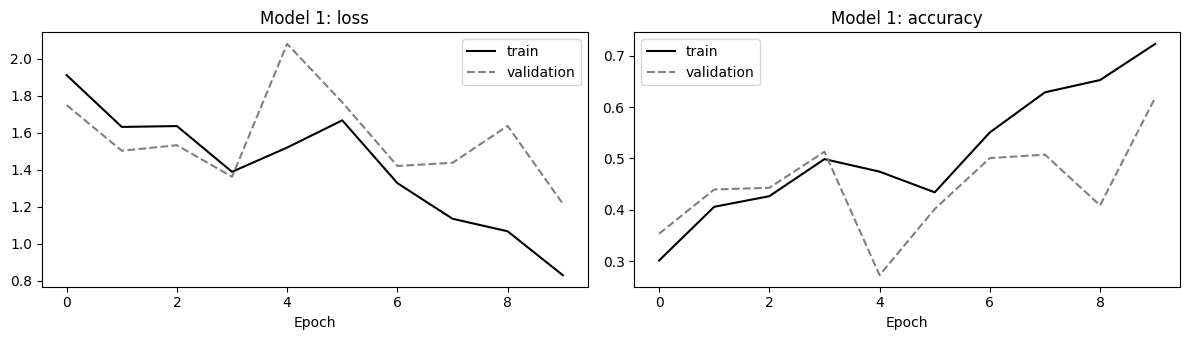

In [20]:
def evaluate(name, y_true, probs):
    # Returns the planned metrics for one model on the test set
    y_pred = probs.argmax(axis=1)
    top3 = np.mean([t in np.argsort(p)[-3:] for t, p in zip(y_true, probs)])
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Macro F1": f1_score(y_true, y_pred, average="macro"),
            "Top-3 Accuracy": top3,
            "Log Loss": log_loss(y_true, probs, labels=list(range(N_CLASSES)))}

def plot_history(hist, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for ax, m in zip(axes, ["loss", "accuracy"]):
        ax.plot(hist.history[m], color="black", label="train")
        ax.plot(hist.history[f"val_{m}"], color="grey", linestyle="--", label="validation")
        ax.set_title(f"{title}: {m}"); ax.set_xlabel("Epoch"); ax.legend()
    plt.tight_layout(); plt.show()

probs_m1 = model_1.predict(X_test_1, verbose=0)
results = [evaluate("Benchmark: TF-IDF + Logistic Regression", y_test, probs_bench),
           evaluate("Model 1: LSTM (first 300 tokens)", y_test, probs_m1)]
display(pd.DataFrame(results).round(4))
plot_history(hist_1, "Model 1")

**My comment on Model 1:** [Interpret after running.] The points I look for are: (1) whether validation loss starts rising while training loss keeps falling, which signals overfitting because Model 1 has no dropout; (2) the gap to the benchmark, because Model 1 only reads 300 of the 1,000 words, so it sees less than a third of the evidence the TF-IDF model sees; and (3) whether smaller authors have low recall, since Model 1 has no class weights. These shortcomings define the retrain.

### 4.2 Retraining: Model 2 (Windowed Bidirectional LSTM)

| Shortcoming of Model 1 | Change in Model 2 |
|:---|:---|
| Reads only the first 300 of ~1,000 words | Each fragment is cut into 250-word windows and **all** windows are used; test predictions average the window probabilities per fragment |
| Reads left to right only | Two stacked **bidirectional** LSTM layers |
| No regularisation, risk of overfitting | SpatialDropout (0.2), Dropout (0.4 and 0.3), EarlyStopping restoring the best weights |
| Smaller authors under-predicted | Balanced class weights |
| Fixed learning rate | ReduceLROnPlateau and gradient clipping |

Windows are created **after** the train, validation and test split, so no part of a test fragment is ever seen in training.

In [21]:
WIN = 250

def make_windows(df, win=WIN, min_len=100):
    # Splits each fragment into non-overlapping windows and remembers which fragment each came from
    texts, labels, doc_ids = [], [], []
    for doc_id, (t, l) in enumerate(zip(df["text"].values, df["label"].values)):
        toks = t.split()
        for start in range(0, len(toks), win):
            chunk = toks[start:start + win]
            if len(chunk) >= min_len:
                texts.append(" ".join(chunk)); labels.append(l); doc_ids.append(doc_id)
    return np.array(texts), np.array(labels), np.array(doc_ids)

vectoriser_2 = layers.TextVectorization(standardize=None, split="whitespace", output_mode="int",
                                        output_sequence_length=WIN, vocabulary=SELECTED_VOCAB)

tr_txt, y_train_w, _ = make_windows(train_df)
va_txt, y_val_w, _   = make_windows(val_df)
X_train_2 = vectoriser_2(tr_txt).numpy()
X_val_2   = vectoriser_2(va_txt).numpy()
print(f"Training windows: {len(X_train_2):,} (from {len(train_df):,} fragments)")

weights = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_train_w)
CLASS_WEIGHTS = dict(enumerate(weights))

Training windows: 79,591 (from 19,903 fragments)


Model: "model_2_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 250)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 250, 128)  │  1,271,296 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d   │ (None, 250, 128)  │          0 │ embedding_1[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 250)       │          0 │ input_layer_1[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 250, 128)  │     98,816 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 64)        │     41,216 │ bidirectional[0]… │
│ (Bidirectional)     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      4,160 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 10)        │        650 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,416,138 (5.40 MB)

 Trainable params: 1,416,138 (5.40 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
622/622 - 37s - 59ms/step - accuracy: 0.3523 - loss: 1.6119 - top3: 0.7323 - val_accuracy: 0.5213 - val_loss: 1.2691 - val_top3: 0.8822 - learning_rate: 0.0010
Epoch 2/20
622/622 - 32s - 52ms/step - accuracy: 0.5332 - loss: 1.1321 - top3: 0.9030 - val_accuracy: 0.5832 - val_loss: 1.0168 - val_top3: 0.9109 - learning_rate: 0.0010
Epoch 3/20
622/622 - 42s - 67ms/step - accuracy: 0.6159 - loss: 0.9329 - top3: 0.9331 - val_accuracy: 0.7002 - val_loss: 0.8438 - val_top3: 0.9384 - learning_rate: 0.0010
Epoch 4/20
622/622 - 33s - 52ms/step - accuracy: 0.6993 - loss: 0.7698 - top3: 0.9440 - val_accuracy: 0.7535 - val_loss: 0.7114 - val_top3: 0.9482 - learning_rate: 0.0010
Epoch 5/20
622/622 - 33s - 54ms/step - accuracy: 0.7604 - loss: 0.6330 - top3: 0.9540 - val_accuracy: 0.7729 - val_loss: 0.6887 - val_top3: 0.9517 - learning_rate: 0.0010
Epoch 6/20
622/622 - 35s - 57ms/step - accuracy: 0.8266 - loss: 0.5155 - top3: 0.9612 - val_accuracy: 0.8358 - val_loss: 0.5533 - val_top3: 0.958

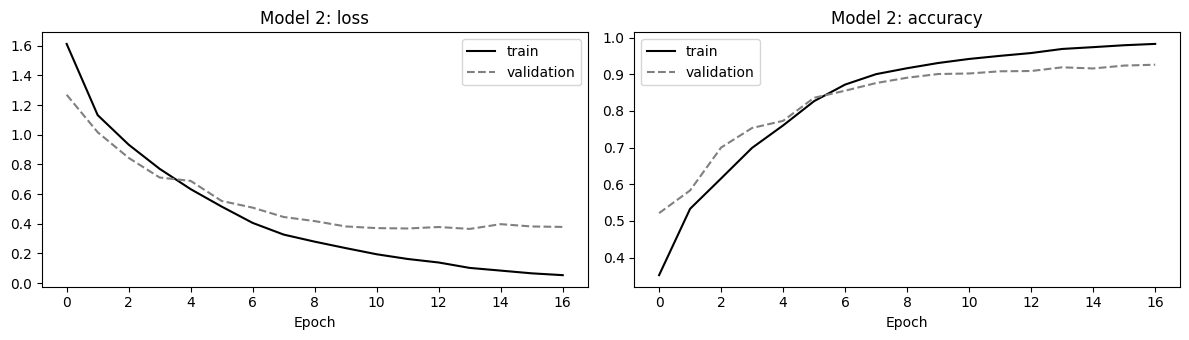

In [22]:
# Attribution: stacked bidirectional pattern adapted from the Keras documentation and Chollet (2021)
def build_model_2(vocab_size, n_classes, maxlen):
    inputs  = layers.Input(shape=(maxlen,), dtype="int64")
    x = layers.Embedding(vocab_size, 128, mask_zero=True)(inputs)
    x = layers.SpatialDropout1D(0.2)(x)                                   # drops whole embedding channels
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)   # reads forwards and backwards
    x = layers.Bidirectional(layers.LSTM(32))(x)                          # summarises the sequence
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="model_2_bilstm")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3")])
    return model

model_2 = build_model_2(VOCAB_SIZE, N_CLASSES, WIN)
model_2.summary()

callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
             keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5)]

hist_2 = model_2.fit(X_train_2, y_train_w, validation_data=(X_val_2, y_val_w),
                     epochs=20, batch_size=128, class_weight=CLASS_WEIGHTS,
                     callbacks=callbacks, verbose=2)
plot_history(hist_2, "Model 2")

In [23]:
def fragment_probs(model, vec, df, min_len=100):
    # Predicts every window, then averages window probabilities back to one prediction per fragment
    texts, _, doc_ids = make_windows(df, min_len=min_len)
    p = model.predict(vec(texts).numpy(), batch_size=256, verbose=0)
    return pd.DataFrame(p).groupby(doc_ids).mean().values

probs_m2 = fragment_probs(model_2, vectoriser_2, test_df)
results.append(evaluate("Model 2: Windowed BiLSTM (retrained)", y_test, probs_m2))

### 4.3 Model Comparison, Classification Report and Confusion Matrix

,Model,Accuracy,Macro F1,Top-3 Accuracy,Log Loss
0,Benchmark: TF-IDF + Logistic Regression,0.9871,0.9854,0.9984,0.1086
1,Model 1: LSTM (first 300 tokens),0.6080,0.5229,0.8523,1.2146
2,Model 2: Windowed BiLSTM (retrained),0.9794,0.9773,0.9944,0.1363


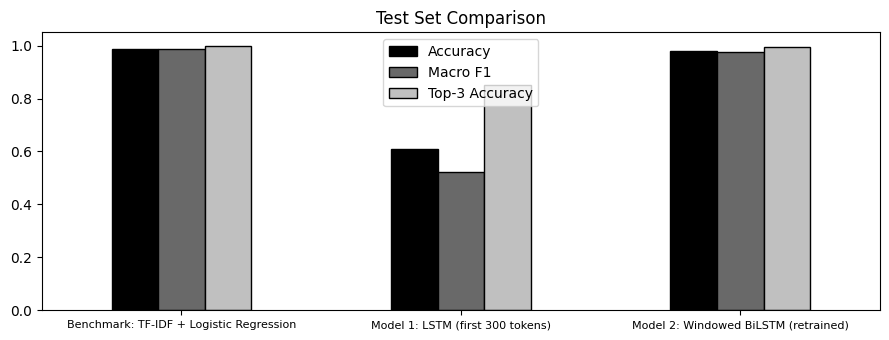

In [24]:
comparison = pd.DataFrame(results).round(4)
display(comparison)

fig, ax = plt.subplots(figsize=(9, 3.5))
comparison.set_index("Model")[["Accuracy", "Macro F1", "Top-3 Accuracy"]].plot(
    kind="bar", ax=ax, color=["black", "dimgrey", "silver"], edgecolor="black")
ax.set_ylim(0, 1.05); ax.set_title("Test Set Comparison"); ax.set_xlabel("")
plt.xticks(rotation=0, fontsize=8); plt.tight_layout(); plt.show()

              precision    recall  f1-score   support

    Author_8      0.991     0.963     0.977      1037
   Author_14      0.985     0.998     0.991       405
   Author_19      0.970     0.983     0.976       231
   Author_21      0.997     0.980     0.988       346
   Author_26      0.997     1.000     0.999       666
   Author_33      0.962     0.977     0.970       262
   Author_37      0.955     0.950     0.952       358
   Author_39      0.985     0.979     0.982       340
   Author_45      0.969     0.983     0.976       347
   Author_48      0.928     0.996     0.961       273

    accuracy                          0.979      4265
   macro avg      0.974     0.981     0.977      4265
weighted avg      0.980     0.979     0.979      4265



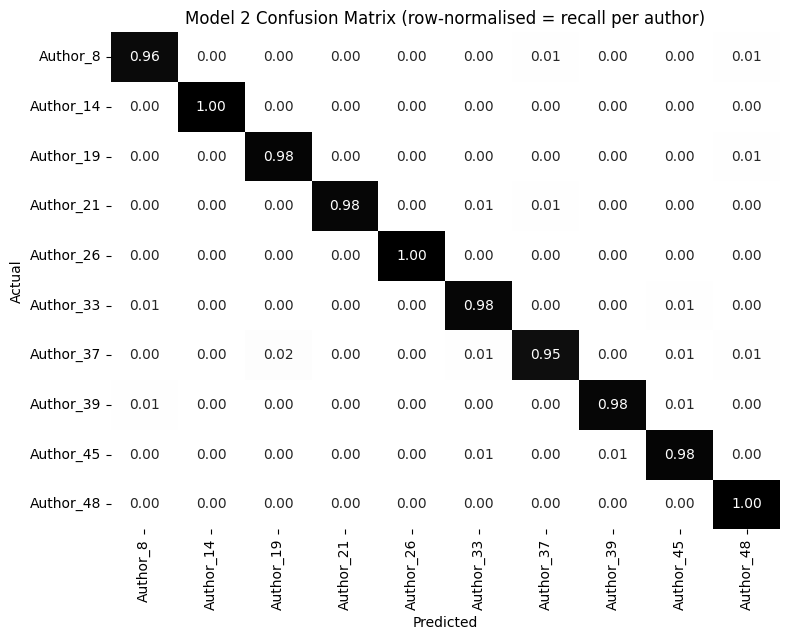

In [25]:
# Detailed results for the retrained LSTM
y_pred_m2 = probs_m2.argmax(axis=1)
print(classification_report(y_test, y_pred_m2, target_names=CLASS_NAMES, digits=3))

cm = confusion_matrix(y_test, y_pred_m2, normalize="true")
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Greys",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
plt.title("Model 2 Confusion Matrix (row-normalised = recall per author)")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

**My comment:** [Interpret after running.] I read the comparison in this order:

1. **Did the retrain fix Model 1?** Compare macro F1 and the learning curves of Model 1 and Model 2. Reading the full fragment and adding regularisation should raise macro F1 and narrow the train and validation gap.
2. **How does the LSTM compare to the benchmark?** If the TF-IDF model is still ahead, this is consistent with Badirli et al. (2021), and it tells the client that the strength of the LSTM lies in its ability to judge short, pasted passages in context, while the linear model is a strong, cheap alternative for full fragments.
3. **Which authors are confused?** The off-diagonal cells in the confusion matrix show which pairs of authors write most alike [name the pair after running].
4. **Top-3 accuracy** is the number that matters most for fans, because the bot always shows three guesses.

### 4.4 Overfitting Check

In [26]:
gaps = []
for name, h in [("Model 1", hist_1), ("Model 2", hist_2)]:
    best = int(np.argmin(h.history["val_loss"]))
    gaps.append({"Model": name, "Best epoch": best + 1,
                 "Train accuracy": h.history["accuracy"][best],
                 "Validation accuracy": h.history["val_accuracy"][best],
                 "Gap": h.history["accuracy"][best] - h.history["val_accuracy"][best]})
display(pd.DataFrame(gaps).round(4))

,Model,Best epoch,Train accuracy,Validation accuracy,Gap
0,Model 1,10,0.7229,0.6183,0.1046
1,Model 2,14,0.9689,0.9188,0.0501


**My comment:** [Interpret after running.] A gap of a few percentage points indicates a model that generalises. Note that Model 2's training accuracy is measured with dropout active, so its true training accuracy is higher than shown. The remaining caveat is fragment leakage within books (Section 1.4), which means real-world performance on unseen books may be lower than these scores.

### 4.5 The Fan Bot: `guess_author()`

This is the deliverable fans interact with. It cleans a pasted passage exactly as the training data was cleaned, averages the model's predictions over its windows, and shows the top three authors. If the model is not confident, the bot says so, which covers the open-set risk of a fan pasting an author the model has never seen.

In [27]:
def guess_author(passage, model=model_2, vec=vectoriser_2, k=3, threshold=0.40):
    clean = re.sub(r"\s+", " ", re.sub(r"[^a-z\s]", " ", passage.lower())).strip()
    if len(clean.split()) < 50:
        print("Please paste a longer passage (at least 50 words) so I can judge the style.")
        return
    probs = fragment_probs(model, vec, pd.DataFrame({"text": [clean], "label": [0]}), min_len=1)[0]
    top = np.argsort(probs)[::-1][:k]
    print("My guesses:")
    for rank, idx in enumerate(top, 1):
        print(f"  {rank}. {CLASS_NAMES[idx]:<12} {probs[idx]:.1%}")
    if probs[top[0]] < threshold:
        print("I'm not very confident. This might be an author I haven't read yet.")

# Demo on a random fragment the model has never seen
sample = test_df.sample(1, random_state=7).iloc[0]
print("True author:", CLASS_NAMES[sample["label"]])
guess_author(" ".join(sample["text"].split()[:250]))

True author: Author_26
My guesses:
  1. Author_26    100.0%
  2. Author_8     0.0%
  3. Author_19    0.0%


In [28]:
# Saving the final model and vocabulary for the GitHub submission
model_2.save("author_bilstm_model2.keras")
pd.Series(SELECTED_VOCAB).to_csv("selected_vocabulary.csv", index=False, header=["word"])
comparison.to_csv("model_comparison.csv", index=False)
spark.stop()

## 5 Summary of Findings for the Report

| Area | Finding |
|:---|:---|
| Data | [n] labelled fragments, [N] authors kept, [n] records after cleaning |
| Cleaning | [n] duplicates and [n] short or padded fragments removed; Latin-1 encoding handled |
| EDA | Authors differ in type-token ratio, word length and function word habits; stopwords retained |
| Feature selection | [n] of 10,000 words significant at p < 0.05; final vocabulary [n] words |
| Model 1 | Macro F1 [x], top-3 [x]; limited by reading 300 words and no regularisation |
| Model 2 | Macro F1 [x], top-3 [x]; windowing, BiLSTM, dropout and class weights improved [metric] |
| Benchmark | TF-IDF and Logistic Regression macro F1 [x] |
| Hardest authors | [Author pair] most often confused |

## 6 Conclusion

This part of the POE built an author identification bot for a book press using an LSTM Recurrent Neural Network on the Victorian Era Authorship Attribution dataset. The dataset was selected because it is curated, documented and citable, contains long labelled text fragments well above the 10,000 record minimum, and has already had names and rare words stripped, which pushes any model towards genuine writing style.

Spark was used for loading, EDA, cleaning and chi-square feature selection. The EDA showed that authors differ measurably in vocabulary richness and in function word habits, which led to the key design choice of keeping stopwords, the opposite of my previous sentiment POE. The baseline LSTM was then retrained to use the full fragment through windowing, to read in both directions, and to control overfitting and class imbalance. [Add the headline result after running.]

The main limitations are the lack of book IDs, which prevents a book-level split, the removal of punctuation by the dataset creators, and the closed set of authors. Next steps would be to request the book-level metadata from the creators, add character-level inputs to capture spelling habits, and extend the bot to more authors from the press's own catalogue.

## 7 Reference List

Anthropic (2026) Claude Opus 5.5 [Large language model]. Prompt: 'Help me find a dependable open dataset with a minimum of 10,000 records that is suitable for training an LSTM'Available at: https://claude.ai (Accessed: 20 September 2026).

Apache Software Foundation (2024) *MLlib: Basic statistics, hypothesis testing*. Available at: https://spark.apache.org/docs/latest/ml-statistics.html (Accessed: 20 September 2026).

Badirli, S., Borgo Ton, M., Gungor, A. and Dundar, M. (2021) 'Open set authorship attribution toward demystifying Victorian periodicals', in Lladós, J., Lopresti, D. and Uchida, S. (eds) *Document Analysis and Recognition: ICDAR 2021*. Cham: Springer, pp. 221-235. doi: 10.1007/978-3-030-86337-1_15.

Bengio, Y., Simard, P. and Frasconi, P. (1994) 'Learning long-term dependencies with gradient descent is difficult', *IEEE Transactions on Neural Networks*, 5(2), pp. 157-166.

Burrows, J. (2002) ''Delta': a measure of stylistic difference and a guide to likely authorship', *Literary and Linguistic Computing*, 17(3), pp. 267-287.

Chollet, F. (2021) *Deep Learning with Python*. 2nd edn. Shelter Island: Manning.

Gungor, A. (2018a) *Victorian Era Authorship Attribution*. UCI Machine Learning Repository. doi: 10.24432/C5SW4H. Available at: https://archive.ics.uci.edu/dataset/454/victorian+era+authorship+attribution (Accessed: 20 September 2026).

Gungor, A. (2018b) *Benchmarking authorship attribution techniques using over a thousand books by fifty Victorian era novelists*. MSc thesis. Purdue University.

Hochreiter, S. and Schmidhuber, J. (1997) 'Long short-term memory', *Neural Computation*, 9(8), pp. 1735-1780.

Kingma, D.P. and Ba, J. (2015) 'Adam: a method for stochastic optimization', *Proceedings of the 3rd International Conference on Learning Representations (ICLR)*.

Mosteller, F. and Wallace, D.L. (1964) *Inference and Disputed Authorship: The Federalist*. Reading, MA: Addison-Wesley.

Pedregosa, F. et al. (2011) 'Scikit-learn: machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825-2830.

Prechelt, L. (1998) 'Early stopping, but when?', in Orr, G.B. and Müller, K.R. (eds) *Neural Networks: Tricks of the Trade*. Berlin: Springer, pp. 55-69.

Republic of South Africa (2013) *Protection of Personal Information Act 4 of 2013*. Pretoria: Government Printer.

Schuster, M. and Paliwal, K.K. (1997) 'Bidirectional recurrent neural networks', *IEEE Transactions on Signal Processing*, 45(11), pp. 2673-2681.

Sokolova, M. and Lapalme, G. (2009) 'A systematic analysis of performance measures for classification tasks', *Information Processing and Management*, 45(4), pp. 427-437.

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I. and Salakhutdinov, R. (2014) 'Dropout: a simple way to prevent neural networks from overfitting', *Journal of Machine Learning Research*, 15, pp. 1929-1958.

Stamatatos, E. (2009) 'A survey of modern authorship attribution methods', *Journal of the American Society for Information Science and Technology*, 60(3), pp. 538-556.

Yang, Y. and Pedersen, J.O. (1997) 'A comparative study on feature selection in text categorization', *Proceedings of the 14th International Conference on Machine Learning (ICML)*, pp. 412-420.

Zaharia, M. et al. (2016) 'Apache Spark: a unified engine for big data processing', *Communications of the ACM*, 59(11), pp. 56-65.